In [11]:
%pip -q install -U pymupdf tiktoken google-genai pandas tqdm

In [12]:
import re
import os
import json
import time
import hashlib
from pathlib import Path

import pymupdf
import tiktoken
import pandas as pd

from tqdm.auto import tqdm
from google import genai
from google.genai import types
from google.colab import userdata
from IPython.display import display, Markdown

# Configuration
PDF = Path("/content/ITALY.pdf")
OUT = Path("/content/italy_task1")
CACHE = OUT / "cache"

CACHE.mkdir(parents=True, exist_ok=True)

MODEL = "gemini-3.5-flash-lite"
enc = tiktoken.get_encoding("cl100k_base")

# Verify the existing PDF.
if not PDF.is_file():
    raise FileNotFoundError(
        f"File not found: {PDF}. Check the exact filename in Colab."
    )

if PDF.stat().st_size < 1000:
    raise ValueError("The PDF is empty or incomplete.")

# Clean extracted text without altering economic values.
def clean_text(text):
    """Remove PDF formatting noise and recurring page headers."""

    text = text.replace("\u00ad", "").replace("\u00a0", " ")
    text = re.sub(r"(?<=[A-Za-z])-\n(?=[a-z])", "", text)

    lines = []

    for line in text.splitlines():
        line = re.sub(r"[ \t]+", " ", line).strip()

        if re.fullmatch(
            r"ITALY|INTERNATIONAL MONETARY FUND|"
            r"\d+\s+INTERNATIONAL MONETARY FUND|"
            r"INTERNATIONAL MONETARY FUND\s+\d+",
            line,
            re.IGNORECASE
        ):
            continue

        lines.append(line)

    return re.sub(r"\n{3,}", "\n\n", "\n".join(lines)).strip()


# Extract text from the complete IMF report.
try:
    with pymupdf.open(PDF) as document:

        page_count = document.page_count

        if page_count == 0:
            raise ValueError(
                "The PDF has 0 pages. The file in Colab may be "
                "corrupted or incompletely downloaded."
            )

        pages = [
            {
                "page": i + 1,
                "text": clean_text(page.get_text("text", sort=True))
            }
            for i, page in enumerate(document)
        ]

except Exception as error:
    print(f"Filename: {PDF.name}")
    print(f"File size: {PDF.stat().st_size:,} bytes")
    raise RuntimeError(
        "Could not read the existing PDF. Verify that "
        "ITALY.pdf is a complete, valid PDF document."
    ) from error

# Validate the correct IMF report.
if "23/273" not in pages[0]["text"]:
    raise ValueError(
        "The PDF does not match IMF Italy Country Report No. 23/273."
    )

# Preserve page numbers for summarisation and evaluation.
full_text = "\n\n".join(
    f"[PDF PAGE {page['page']}]\n{page['text']}"
    for page in pages
)

# Save cleaned outputs.
(OUT / "cleaned_report.txt").write_text(
    full_text, encoding="utf-8"
)

(OUT / "pages.json").write_text(
    json.dumps(pages, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Display processing results.
print("=" * 45)
print("TASK 1 — PDF EXTRACTION SUCCESSFUL")
print("=" * 45)
print(f"Filename       : {PDF.name}")
print(f"Pages          : {len(pages)}")
print(f"Characters     : {len(full_text):,}")
print(f"Tokens         : {len(enc.encode(full_text)):,}")
print(f"Output folder  : {OUT}")
print("=" * 45)

TASK 1 — PDF EXTRACTION SUCCESSFUL
Filename       : ITALY.pdf
Pages          : 99
Characters     : 214,664
Tokens         : 51,914
Output folder  : /content/italy_task1


In [13]:
# Create overlapping text chunks while preserving PDF page numbers.
CHUNK_SIZE = 450
OVERLAP = 50
chunks = []

for page in pages:
    tokens = enc.encode(page["text"])

    for start in range(0, len(tokens), CHUNK_SIZE - OVERLAP):
        part = tokens[start:start + CHUNK_SIZE]

        chunks.append({
            "chunk_id": len(chunks) + 1,
            "page": page["page"],
            "token_count": len(part),
            "text": enc.decode(part)
        })

        if start + CHUNK_SIZE >= len(tokens):
            break

# Identify the actual chapters and annexes in the IMF report.
# False indicates a structural boundary, not a section to summarise.
HEADINGS = [
    ("Press Release", r"^\s*PR23/273\s*$", True),
    ("Key Issues", r"^\s*KEY ISSUES\s*$", True),
    ("Contents", r"^\s*CONTENTS\s*$", False),
    ("Context", r"^\s*CONTEXT\s*$", True),
    ("Recent Developments", r"^\s*RECENT DEVELOPMENTS\s*$", True),
    ("Outlook and Risks", r"^\s*A\.\s*Outlook and Risks\s*$", True),
    ("Fiscal Policy", r"^\s*B\.\s*Fiscal Policy to Navigate Shocks and Preserve Sustainability\s*$", True),
    ("Financial Sector Resilience", r"^\s*C\.\s*Ensuring Financial Sector Resilience\s*$", True),
    ("Structural Priorities", r"^\s*D\.\s*Structural Priorities\s*$", True),
    ("Staff Appraisal", r"^\s*STAFF APPRAISAL\s*$", True),
    ("Figures and Tables", r"^\s*Figure 1\. Italy: Real Sector Developments\s*$", False),
    *[(f"Annex {n}", rf"^\s*Annex {n}\.\s+", True)
      for n in ("I", "II", "III", "IV", "V", "VI", "VII", "VIII")],
    ("Informational Annex",
     r"^\s*STAFF REPORT FOR THE 2023 ARTICLE IV CONSULTATION—\s*$", True),
    ("Executive Director Statement",
     r"^\s*Statement by Mr\. Giammusso on Italy\s*$", True)
]

# Find each heading in the extracted document.
positions = []

for title, pattern, include in HEADINGS:
    for i, page in enumerate(pages):
        match = re.search(pattern, page["text"], re.I | re.M)

        if match:
            positions.append((i, match.start(), title, include))
            break

positions.sort()

# Extract complete section text without duplicating adjacent sections.
sections = []

for k, (start_page, start_pos, title, include) in enumerate(positions):
    if not include:
        continue

    if k + 1 < len(positions):
        end_page, end_pos = positions[k + 1][:2]
    else:
        end_page = len(pages) - 1
        end_pos = len(pages[-1]["text"])

    parts = []

    for i in range(start_page, end_page + 1):
        left = start_pos if i == start_page else 0
        right = end_pos if i == end_page else len(pages[i]["text"])

        if right > left:
            parts.append(pages[i]["text"][left:right])

    sections.append({
        "section": title,
        "start_page": start_page + 1,
        "end_page": end_page + 1,
        "text": "\n\n".join(parts).strip()
    })

# Validate extraction and store reusable outputs.
required = {title for title, _, include in HEADINGS if include}
found = {section["section"] for section in sections}

if required - found:
    raise ValueError(f"Missing sections: {sorted(required - found)}")

assert chunks and all(c["token_count"] <= CHUNK_SIZE for c in chunks)
assert all(s["text"] for s in sections)

(OUT / "chunks.json").write_text(
    json.dumps(chunks, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(OUT / "sections.json").write_text(
    json.dumps(sections, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("=" * 45)
print("TASK 1 — CHUNKING COMPLETED")
print("=" * 45)
print(f"PDF              : {PDF.name}")
print(f"Total chunks     : {len(chunks)}")
print(f"Chunk size       : {CHUNK_SIZE} tokens")
print(f"Token overlap    : {OVERLAP}")
print(f"Sections found   : {len(sections)}")
print("-" * 45)

for section in sections:
    print(f"✓ {section['section']}")

print("=" * 45)

TASK 1 — CHUNKING COMPLETED
PDF              : ITALY.pdf
Total chunks     : 174
Chunk size       : 450 tokens
Token overlap    : 50
Sections found   : 19
---------------------------------------------
✓ Press Release
✓ Key Issues
✓ Context
✓ Recent Developments
✓ Outlook and Risks
✓ Fiscal Policy
✓ Financial Sector Resilience
✓ Structural Priorities
✓ Staff Appraisal
✓ Annex I
✓ Annex II
✓ Annex III
✓ Annex IV
✓ Annex V
✓ Annex VI
✓ Annex VII
✓ Annex VIII
✓ Informational Annex
✓ Executive Director Statement


In [16]:
# Connect to Gemini using the existing Colab Secret.
API_KEY = userdata.get("GoogleGeminiAPI")

if not API_KEY:
    raise ValueError("GoogleGeminiAPI not found in Colab Secrets.")

client = genai.Client(api_key=API_KEY)

MODEL = "gemini-3.5-flash-lite"

ANALYST = """
You are an IMF macroeconomic and financial stability analyst.
Use only evidence from Italy's 2023 IMF Article IV report.
Preserve exact figures, years, percentages and forecast labels.
Identify economic findings, financial risks and IMF recommendations.
Never invent facts or introduce unsupported information.
"""

# Generate reliable responses with local caching and retries.
def generate(prompt, limit=500):
    key = hashlib.sha256(
        json.dumps([MODEL, ANALYST, prompt, limit]).encode()
    ).hexdigest()

    cache_file = CACHE / f"{key}.txt"

    if cache_file.exists():
        return cache_file.read_text(encoding="utf-8")

    for attempt in range(4):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=ANALYST,
                    temperature=0.1,
                    max_output_tokens=limit,
                    thinking_config=types.ThinkingConfig(
                        thinking_level="MINIMAL"
                    )
                )
            )

            result = (response.text or "").strip()

            if not result:
                raise ValueError("Gemini returned an empty response.")

            cache_file.write_text(result, encoding="utf-8")
            return result

        except Exception:
            if attempt == 3:
                raise
            time.sleep(3 * (2 ** attempt))


# Summarise every major section without discarding long sections.
def summarise_section(section):
    tokens = enc.encode(section["text"])

    # Process lengthy sections in manageable evidence windows.
    windows = [
        enc.decode(tokens[i:i + 5500])
        for i in range(0, len(tokens), 5500)
    ]

    if len(windows) > 1:
        notes = []

        for text in windows:
            notes.append(generate(
                "Extract the key findings, numerical evidence, "
                "financial risks and recommendations in about "
                "100 words. Use only this text:\n\n" + text,
                limit=350
            ))

        evidence = "\n\n".join(notes)
    else:
        evidence = windows[0]

    summary = generate(
        f"Summarise the IMF section '{section['section']}' "
        "in fewer than 100 words. Include the principal findings, "
        "financial risks and policy implications. "
        "Preserve exact economic figures and years. "
        "Return one concise paragraph.\n\n"
        f"SOURCE EVIDENCE:\n{evidence}",
        limit=350
    )

    # Enforce the assignment's strict word limit.
    for attempt in range(3):
        if len(summary.split()) < 100:
            break

        summary = generate(
            f"Revision {attempt + 1}: Rewrite the following "
            "in fewer than 85 words. Preserve factual accuracy. "
            "Return only the paragraph:\n\n" + summary,
            limit=250
        )

    if len(summary.split()) >= 100:
        raise ValueError(
            f"Summary exceeds 99 words: {section['section']}"
        )

    return {
        "section": section["section"],
        "start_page": section["start_page"],
        "end_page": section["end_page"],
        "word_count": len(summary.split()),
        "summary": summary
    }


# Generate summaries for all identified sections.
section_summaries = [
    summarise_section(section)
    for section in tqdm(sections, desc="Summarising IMF sections")
]

# Save section summaries.
(OUT / "section_summaries.json").write_text(
    json.dumps(section_summaries, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Combine findings across the complete report.
evidence = "\n\n".join(
    f"{s['section']} (PDF pages {s['start_page']}–{s['end_page']}): "
    f"{s['summary']}"
    for s in section_summaries
)

# Generate a consolidated executive summary.
executive_summary = generate(
    """
Prepare 7 concise executive bullet points summarising
Italy's 2023 IMF Article IV report.

Cover:
1. Economic growth and outlook.
2. Inflation and monetary conditions.
3. Banking stability and credit risks.
4. Public debt and fiscal sustainability.
5. Employment and structural challenges.
6. Systemic financial vulnerabilities.
7. IMF policy recommendations.

Use only the supplied evidence.
Preserve numerical accuracy and reporting years.
Distinguish historical observations from forecasts.

SOURCE EVIDENCE:
""" + evidence,
    limit=1200
)

# Save executive summary.
(OUT / "executive_summary.md").write_text(
    executive_summary,
    encoding="utf-8"
)

# Display results.
display(Markdown("## Italy — IMF Executive Summary"))
display(Markdown(executive_summary))

display(Markdown("## Major Section Summaries"))

for item in section_summaries:
    display(Markdown(
        f"**{item['section']}** "
        f"({item['word_count']} words)\n\n"
        f"{item['summary']}"
    ))

print("\n" + "=" * 45)
print("TASK 1 — SUMMARISATION COMPLETED")
print("=" * 45)
print(f"Model             : {MODEL}")
print(f"PDF               : {PDF.name}")
print(f"Sections processed: {len(section_summaries)}")
print("Section word limit: Fewer than 100 words")
print("Executive summary : Saved")
print(f"Output folder     : {OUT}")
print("=" * 45)

Summarising IMF sections:   0%|          | 0/19 [00:00<?, ?it/s]

## Italy — IMF Executive Summary

* **Economic growth and outlook:** Italy's economy grew by 3.7 percent in 2022 (with output expanding by 1.9 percent y/y in Q1: 2023), driven by strong domestic demand, employment recovery, and tourism. However, growth is forecast to moderate to 1.1 percent in 2023 and 0.9 percent in 2024 (or average 1.0 percent in 2023–24) as policy support is scaled back, remaining around 1.1 percent from 2025. Downside risks dominate, driven by tighter monetary policy, higher borrowing costs, renewed global financial stress, and delayed NextGenerationEU disbursements.
* **Inflation and monetary conditions:** Headline inflation peaked at 12½ percent in fall 2022 before easing to 6.7 percent in June 2023, while core inflation reached 6.0 percent y/y in June 2023. Headline inflation is projected at 5.2 percent in 2023 and 2.5 percent in 2024, with core inflation staying above 2 percent through 2025. Monetary conditions have tightened alongside rising policy rates, quantitative tightening, and sharply tightened bank lending conditions since Q2:2022.
* **Banking stability and credit risks:** Italy’s financial sector has strengthened, with significant institutions recording a net non-performing loan ratio of 1.1 percent in March 2023 and a capital adequacy ratio of 15.4 percent in March 2023. Nevertheless, financial risks include potential credit volume declines, rising non-performing loans, higher funding costs, unrealized fixed-income losses, commercial real estate vulnerabilities (where CRE accounts for 22 percent of NPLs), and bank-government funding competition.
* **Public debt and fiscal sustainability:** Italy's headline deficit averaged 8.9 percent of GDP during 2020–22, while public debt declined to 144 percent of GDP in 2022 and stands at 140.5 percent of GDP in 2023. The medium-term sovereign stress risk is moderate yet borderline, compounded by high gross financing needs, long-term debt pressures from rising pension spending, a shrinking workforce, and TARGET2 liabilities reaching 36 percent of GDP.
* **Employment and structural challenges:** Italy faces structural growth challenges from population aging—with the working-age population forecast to shrink by nearly 20 percent over the next 25 years—low labor force participation, and weak productivity, alongside an underground and informal economy accounting for 11 percent of GDP and micro firms holding back productivity. Additional risks include transnational corruption, complex financial crimes, energy supply shocks, and administrative strain on municipalities executing the National Recovery and Resilience Plan (NRRP).
* **Systemic financial vulnerabilities:** Principal systemic financial risks involve tighter monetary policy, rising borrowing costs, sovereign-bank-corporate feedback channels, asset quality deterioration, housing market corrections, and risks from virtual assets and low corporate anti-corruption fines. Furthermore, the Bank of Italy's 2022 profits dropped to €2.1bn (from €5.9bn in 2021) due to rising policy rates, with projected 2023–24 losses fully covered by €35bn in general risk provisions.
* **IMF policy recommendations:** The IMF recommends frontloading fiscal adjustment, saving revenue windfalls to reach a 1 percent primary surplus in 2023, maintaining a primary surplus of 3 percent of GDP from 2025 onwards to reduce debt to around 130 percent of GDP by 2028, and strictly managing public sector guarantees. Additional recommendations include base-broadening tax and pension reforms, maintaining bank capital and liquidity headroom, avoiding a windfall tax, implementing ambitious structural reforms under the NRRP (backed by EU grants and loans totaling around 10 percent of GDP) to boost productivity, strengthening AML/CFT and anti-corruption frameworks, and accelerating renewable energy.

## Major Section Summaries

**Press Release** (89 words)

Italy's economy grew by 3.7 percent in 2022, but growth is forecast to moderate to 1.1 percent in 2023 and 0.9 percent in 2024. Principal financial risks include tighter monetary policy, rising borrowing costs, sovereign-bank-corporate linkages, and high public debt (140.5 percent of GDP in 2023). Headline inflation is projected at 5.2 percent in 2023. IMF recommendations stress frontloading fiscal adjustment, decisive debt reduction, base-broadening tax and pension reforms, limiting public guarantees, maintaining bank capital and liquidity headroom, and implementing ambitious structural reforms to boost productivity and potential growth.

**Key Issues** (88 words)

Output grew robustly in 2022, but scaling back policy support will reduce GDP growth to 1.1 percent in 2023 and 0.9 percent in 2024. Sovereign stress risks are moderate yet borderline, with high public debt and declining bank credit. Financial risks involve tighter financial conditions, bank-government funding competition, and commercial real estate exposures. The IMF recommends front-loaded fiscal adjustment, maintaining a primary surplus of 3 percent of GDP, growth-promoting structural policies, stricter supervision attuned to tighter financial conditions, and prompt reform implementation to lift productivity and potential growth.

... (14 outputs left out)

**Annex VIII** (93 words)

According to the 2023 IMF report, Italy strengthened its legislative framework and enforcement against foreign bribery, establishing a dedicated AML Supervision and Regulation Unit in 2022 and a new UIF Directorate in February 2023. Financial risks stem from a high number of court dismissals in bribery cases, low corporate fines, short corporate statutes of limitations, and risks from virtual assets. Policy recommendations include providing specific judge training, raising compliance awareness, adopting the outstanding Administrative Fees Decree to operationalize the beneficial ownership register established under the March 11, 2022 decree, and enforcing VASP registration.

**Informational Annex** (94 words)

The IMF's Informational Annex for Italy finds that data provision is adequate for surveillance, with comprehensive and high-quality statistics meeting SDDS Plus standards since 2015. Italy participates in the IMF's financial soundness indicators, reporting all 12 core and 11 of 13 encouraged FSIs semi-annually. Regarding statistical issues, the report identifies specific data limitations: quarterly national accounts derive changes in inventories as a residual combined with statistical discrepancies, and government finance statistics lack component details on asset and liability stock positions by counterparty sector. The IMF recommends improving inventory estimates and expanding government finance disclosures.

**Executive Director Statement** (80 words)

Italy’s economy showed resilience with brisk 2022 growth and declining inflation. Financial risks include global geopolitical uncertainty, cyclical slowdowns, and higher interest rates affecting debt servicing, though banks remain sound with a net non-performing loan ratio of 1.5 percent in 2022 (1.1 percent in March 2023 for significant institutions) and a capital adequacy ratio of 15.4 percent in March 2023. Authorities are committed to reducing deficits and debt, phasing out energy support, and implementing the National Recovery and Resilience Plan.


TASK 1 — SUMMARISATION COMPLETED
Model             : gemini-3.5-flash-lite
PDF               : ITALY.pdf
Sections processed: 19
Section word limit: Fewer than 100 words
Executive summary : Saved
Output folder     : /content/italy_task1


In [19]:
# CELL 5 — LLM-as-a-Judge Evaluation and Validation

import json
import re
import time
import hashlib

# Independent evaluation instructions
JUDGE_SYSTEM = """
You are an independent IMF report evaluator.

Compare the summary strictly against the supplied source evidence.

Evaluate:
1. Factual alignment: accuracy of facts, figures and dates.
2. Completeness: coverage of important findings and risks.
3. Consistency: absence of contradictions.

Score each criterion from 1 (poor) to 5 (excellent).
Identify unsupported claims and missing information.
Do not reward fluent but inaccurate summaries.
Return valid JSON only.
"""

METRICS = ["factual_alignment", "completeness", "consistency"]


def select_evidence(source, summary, max_tokens=6500):
    """Retain relevant source passages for factual evaluation."""

    tokens = enc.encode(source)

    if len(tokens) <= max_tokens:
        return source, False

    windows = [
        enc.decode(tokens[i:i + 850])
        for i in range(0, len(tokens), 850)
    ]

    keywords = set(re.findall(r"\b\w{4,}\b", summary.lower()))

    def relevance(text):
        words = set(re.findall(r"\b\w{4,}\b", text.lower()))
        return len(keywords & words)

    ranked = sorted(
        range(len(windows)),
        key=lambda i: relevance(windows[i]),
        reverse=True
    )

    selected = {0, len(windows) - 1}
    selected.update(ranked[:5])

    evidence = "\n\n".join(
        windows[i] for i in sorted(selected)
    )

    return evidence, True


def valid_scores(result):
    """Check the judge's structured numerical scores."""

    return all(
        type(result.get(metric)) is int
        and 1 <= result[metric] <= 5
        for metric in METRICS
    )


def evaluate(summary, source, title):
    """Evaluate accuracy, completeness and consistency."""

    evidence, truncated = select_evidence(source, summary)

    prompt = f"""
Evaluate this IMF summary against the original evidence.

SECTION: {title}

SOURCE EVIDENCE:
{evidence}

GENERATED SUMMARY:
{summary}

Return valid JSON using this structure:

{{
  "factual_alignment": 1,
  "completeness": 1,
  "consistency": 1,
  "unsupported_claims": [],
  "missing_information": [],
  "explanation": "Brief evidence-based explanation"
}}

Score each criterion from 1 to 5.
Identify inaccurate figures, unsupported claims and omissions.
If the supplied evidence is incomplete, state this limitation.
"""

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=JUDGE_SYSTEM,
                    temperature=0,
                    max_output_tokens=900,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            if not valid_scores(result):
                raise ValueError("Invalid judge scores.")

            result["section"] = title
            result["average_score"] = round(
                sum(result[m] for m in METRICS) / 3, 2
            )
            result["evidence_truncated"] = truncated

            return result

        except Exception:
            if attempt == 2:
                raise
            time.sleep(3 * (attempt + 1))


# Load previous evaluation results where available.
evaluation_file = OUT / "judge_evaluations.json"

previous = (
    json.loads(evaluation_file.read_text(encoding="utf-8"))
    if evaluation_file.exists() else []
)

saved = {
    item["fingerprint"]: item
    for item in previous
    if item.get("fingerprint") and valid_scores(item)
}

summaries_by_title = {
    item["section"]: item
    for item in section_summaries
}

evaluations = []

# Evaluate every major IMF section.
for section in tqdm(sections, desc="Evaluating IMF summaries"):

    title = section["section"]
    summary = summaries_by_title[title]["summary"]

    fingerprint = hashlib.sha256(
        (MODEL + JUDGE_SYSTEM + section["text"] + summary)
        .encode("utf-8")
    ).hexdigest()

    if fingerprint in saved:
        result = saved[fingerprint]
    else:
        result = evaluate(summary, section["text"], title)
        result["fingerprint"] = fingerprint

    evaluations.append(result)

    # Save progress after every evaluated section.
    evaluation_file.write_text(
        json.dumps(evaluations, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )


# Evaluate the executive summary.
executive_file = OUT / "executive_evaluation.json"

executive_source = "\n\n".join(
    p["text"] for p in pages
    if p["page"] in (2, 3, 7, 8)
)

executive_source += "\n\n" + "\n\n".join(
    s["text"][:5000]
    for s in sections
    if s["section"] in (
        "Outlook and Risks",
        "Fiscal Policy",
        "Financial Sector Resilience",
        "Structural Priorities",
        "Staff Appraisal"
    )
)

if executive_file.exists():
    executive_evaluation = json.loads(
        executive_file.read_text(encoding="utf-8")
    )

    if not valid_scores(executive_evaluation):
        executive_evaluation = evaluate(
            executive_summary, executive_source, "Executive Summary"
        )
else:
    executive_evaluation = evaluate(
        executive_summary, executive_source, "Executive Summary"
    )

executive_file.write_text(
    json.dumps(executive_evaluation, indent=2, ensure_ascii=False),
    encoding="utf-8"
)


# Calculate evaluation scores without Pandas.
overall = {
    metric: round(
        sum(item[metric] for item in evaluations) / len(evaluations),
        2
    )
    for metric in METRICS
}

overall["mean_judge_score"] = round(
    sum(item["average_score"] for item in evaluations)
    / len(evaluations),
    2
)


# Validate Task 1 requirements.
assert len(pages) > 0
assert len(chunks) > 0
assert len(sections) == len(section_summaries)
assert len(evaluations) == len(sections)
assert all(s["word_count"] < 100 for s in section_summaries)
assert executive_summary.strip()


# Save complete Task 1 results.
results = {
    "country": "Italy",
    "source_pdf": PDF.name,
    "model": MODEL,
    "pdf_pages": len(pages),
    "total_chunks": len(chunks),
    "chunk_size": CHUNK_SIZE,
    "token_overlap": OVERLAP,
    "sections_summarised": len(section_summaries),
    "sections_evaluated": len(evaluations),
    "evaluation_scores": overall,
    "executive_evaluation": executive_evaluation
}

(OUT / "task1_results.json").write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8"
)


# Display evaluation table without Pandas.
print("\n" + "=" * 82)
print("TASK 1 — LLM-AS-A-JUDGE EVALUATION")
print("=" * 82)

print(
    f"{'Section':36}"
    f"{'Factual':>10}"
    f"{'Complete':>11}"
    f"{'Consistent':>13}"
    f"{'Average':>10}"
)

print("-" * 82)

for item in evaluations:
    print(
        f"{item['section'][:36]:36}"
        f"{item['factual_alignment']:>10}"
        f"{item['completeness']:>11}"
        f"{item['consistency']:>13}"
        f"{item['average_score']:>10.2f}"
    )

print("=" * 82)
print("TASK 1 — VALIDATION SUMMARY")
print("=" * 82)

print(f"PDF                 : {PDF.name}")
print(f"Pages processed     : {len(pages)}")
print(f"Chunks generated    : {len(chunks)}")
print(f"Sections summarised : {len(section_summaries)}")
print(f"Sections evaluated  : {len(evaluations)}")
print(f"Factual alignment   : {overall['factual_alignment']}/5")
print(f"Completeness        : {overall['completeness']}/5")
print(f"Consistency         : {overall['consistency']}/5")
print(f"Mean judge score    : {overall['mean_judge_score']}/5")
print(f"Executive score     : {executive_evaluation['average_score']}/5")


# Identify sections needing additional human verification.
flagged = [
    item for item in evaluations
    if item["average_score"] < 4
    or item.get("evidence_truncated", False)
    or item.get("unsupported_claims")
]

print("\nSECTIONS REQUIRING REVIEW")

if flagged:
    for item in flagged:
        print(
            f"- {item['section']}: "
            f"{item['average_score']}/5"
        )

        if item.get("evidence_truncated"):
            print("  Source evidence was shortened for evaluation.")

        for claim in item.get("unsupported_claims", []):
            print(f"  Unsupported claim: {claim}")

else:
    print("No low-scoring or flagged sections detected.")

print("\n" + "=" * 82)
print("TASK 1 — CODE EXECUTION COMPLETED")
print(f"Results saved to: {OUT}")
print("=" * 82)

Evaluating IMF summaries:   0%|          | 0/19 [00:00<?, ?it/s]


TASK 1 — LLM-AS-A-JUDGE EVALUATION
Section                                Factual   Complete   Consistent   Average
----------------------------------------------------------------------------------
Press Release                                5          5            5      5.00
Key Issues                                   5          4            5      4.67
Context                                      5          5            5      5.00
Recent Developments                          5          4            5      4.67
Outlook and Risks                            5          4            5      4.67
Fiscal Policy                                5          4            5      4.67
Financial Sector Resilience                  5          4            5      4.67
Structural Priorities                        5          4            5      4.67
Staff Appraisal                              5          4            5      4.67
Annex I                                      5          4            5 

In [20]:
# TASK 2 — CELL 1: THEMATIC DISTRIBUTION ANALYSIS

import re
import json
from collections import Counter

# Seven financial stability themes required by the assignment.
THEMES = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bcore inflation\b", r"\bprice pressures?\b",
        r"\bprice growth\b", r"\bdisinflation\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bpolicy rates?\b",
        r"\bmonetary policy\b", r"\bcredit growth\b",
        r"\bbank lending\b", r"\bborrowing costs?\b",
        r"\bcredit conditions?\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bproperty market\b", r"\bmortgage[s]?\b",
        r"\bresidential property\b", r"\bconstruction sector\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbank capital\b", r"\bcapital ratios?\b",
        r"\btier 1\b", r"\bcapital adequacy\b",
        r"\bliquidity\b", r"\bnon.performing loans?\b",
        r"\bNPLs?\b", r"\bcapital buffers?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bsovereign debt\b",
        r"\bgovernment debt\b", r"\bdebt sustainability\b",
        r"\bdebt.to.GDP\b", r"\bfiscal deficits?\b",
        r"\bsovereign stress\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabor market\b", r"\blabour market\b",
        r"\bwages?\b", r"\bworkforce\b",
        r"\blabor force\b", r"\bjob vacancies\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risk\b",
        r"\bfinancial stress\b", r"\bfinancial vulnerabilities\b",
        r"\bcontagion\b", r"\bfinancial crisis\b",
        r"\bfinancial fragmentation\b", r"\bdownside risks?\b"
    ]
}

# Scan original cleaned pages, not overlapping chunks.
# This prevents duplicated counts caused by chunk overlap.
theme_results = {}

for theme, patterns in THEMES.items():
    expression = re.compile(
        "|".join(f"(?:{pattern})" for pattern in patterns),
        re.IGNORECASE
    )

    total = 0
    matching_pages = []

    for page in pages:
        matches = list(expression.finditer(page["text"]))

        if matches:
            total += len(matches)
            matching_pages.append(page["page"])

    theme_results[theme] = {
        "count": total,
        "pages": matching_pages
    }

# Calculate thematic distribution percentages.
total_mentions = sum(
    result["count"] for result in theme_results.values()
)

for result in theme_results.values():
    result["percentage"] = round(
        100 * result["count"] / total_mentions, 2
    ) if total_mentions else 0.0

# Save structured, machine-readable results.
theme_output = {
    "country": "Italy",
    "source": PDF.name,
    "pages_scanned": len(pages),
    "method": "Case-insensitive regex occurrence counting",
    "total_mentions": total_mentions,
    "themes": theme_results
}

(OUT / "thematic_distribution.json").write_text(
    json.dumps(theme_output, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Validate all seven mandatory themes.
assert len(theme_results) == 7
assert total_mentions > 0

# Display thematic distribution.
print("=" * 74)
print("TASK 2 — THEMATIC DISTRIBUTION ANALYSIS")
print("=" * 74)
print(f"{'Financial Stability Theme':38} {'Mentions':>10} {'Share (%)':>12}")
print("-" * 74)

for theme, result in sorted(
    theme_results.items(),
    key=lambda item: item[1]["count"],
    reverse=True
):
    print(
        f"{theme:38}"
        f"{result['count']:>10}"
        f"{result['percentage']:>12.2f}"
    )

print("-" * 74)
print(f"{'TOTAL':38}{total_mentions:>10}{100.0:>12.2f}")
print("=" * 74)
print("Seven mandatory themes analysed successfully.")
print(f"Results saved to: {OUT / 'thematic_distribution.json'}")

TASK 2 — THEMATIC DISTRIBUTION ANALYSIS
Financial Stability Theme                Mentions    Share (%)
--------------------------------------------------------------------------
Labor Market Dynamics                         97       24.94
Banking Capital & Liquidity                   83       21.34
Sovereign Debt                                59       15.17
Inflation & Prices                            57       14.65
Interest Rates & Credit                       54       13.88
Systemic Financial Risk                       23        5.91
Housing & Real Estate                         16        4.11
--------------------------------------------------------------------------
TOTAL                                        389      100.00
Seven mandatory themes analysed successfully.
Results saved to: /content/italy_task1/thematic_distribution.json


In [21]:
# TASK 2 — CELL 2: QUALITATIVE RISK EXTRACTION

# Select relevant original IMF evidence with PDF page references.
focus = {
    "Recent Developments", "Outlook and Risks",
    "Fiscal Policy", "Financial Sector Resilience",
    "Structural Priorities", "Staff Appraisal"
}

source_pages = {2, 3, 7, 8}

for section in sections:
    if section["section"] in focus:
        source_pages.update([
            section["start_page"],
            section["start_page"] + 1
        ])

evidence = "\n\n".join(
    f"[PDF PAGE {p['page']}]\n"
    + enc.decode(enc.encode(p["text"])[:650])
    for p in pages
    if p["page"] in source_pages
)

SYSTEM = """
You are an IMF macroeconomic risk analyst.
Extract findings only from the supplied Italy 2023 IMF report.
Distinguish observed economic strengths from future opportunities.
Identify actual vulnerabilities, not hypothetical unsupported risks.
Preserve the report's historical context and factual accuracy.
Return strictly valid JSON.
"""

PROMPT = f"""
Analyse Italy's macroeconomic strengths and systemic vulnerabilities
using only the IMF report evidence below.

Extract:
1. Exactly 6 national economic growth drivers or strengths.
2. Exactly 6 systemic vulnerabilities or economic challenges.

For each item provide:
- insight: one clear, concise sentence.
- evidence: brief explanation supported by the report.
- pdf_page: the supporting PDF page number.

Requirements:
- No duplicated findings.
- No invented statistics or conclusions.
- Distinguish actual findings from projected risks.
- Use PDF page numbers present in the evidence.
- Focus on financial stability and economic implications.

Return JSON with this structure:

{{
  "country": "Italy",
  "report_year": 2023,
  "strengths": [
    {{
      "insight": "...",
      "evidence": "...",
      "pdf_page": 2
    }}
  ],
  "vulnerabilities": [
    {{
      "insight": "...",
      "evidence": "...",
      "pdf_page": 3
    }}
  ]
}}

ORIGINAL IMF EVIDENCE:
{evidence}
"""

# Cache the extraction to avoid unnecessary API requests.
cache_key = hashlib.sha256(
    (MODEL + SYSTEM + PROMPT).encode("utf-8")
).hexdigest()

cache_file = CACHE / f"qualitative_{cache_key}.json"

if cache_file.exists():
    qualitative = json.loads(
        cache_file.read_text(encoding="utf-8")
    )
else:
    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=PROMPT,
                config=types.GenerateContentConfig(
                    system_instruction=SYSTEM,
                    temperature=0.1,
                    max_output_tokens=2000,
                    response_mime_type="application/json"
                )
            )

            qualitative = json.loads(response.text)
            break

        except Exception:
            if attempt == 2:
                raise
            time.sleep(3 * (attempt + 1))

# Validate the required qualitative outputs.
assert qualitative["country"] == "Italy"
assert len(qualitative["strengths"]) == 6
assert len(qualitative["vulnerabilities"]) == 6

for category in ("strengths", "vulnerabilities"):
    for item in qualitative[category]:
        assert item["insight"].strip()
        assert item["evidence"].strip()
        assert item["pdf_page"] in source_pages

# Save validated results.
cache_file.write_text(
    json.dumps(qualitative, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(OUT / "qualitative_risks.json").write_text(
    json.dumps(qualitative, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Display results clearly.
print("=" * 65)
print("TASK 2 — ECONOMIC STRENGTHS AND VULNERABILITIES")
print("=" * 65)

for heading, key in [
    ("ECONOMIC GROWTH DRIVERS AND STRENGTHS", "strengths"),
    ("SYSTEMIC VULNERABILITIES AND CHALLENGES", "vulnerabilities")
]:
    print(f"\n{heading}")
    print("-" * 65)

    for number, item in enumerate(qualitative[key], 1):
        print(f"\n{number}. {item['insight']}")
        print(f"   Evidence: {item['evidence']}")
        print(f"   IMF PDF page: {item['pdf_page']}")

print("\n" + "=" * 65)
print("Qualitative extraction completed.")
print("Strengths identified: 6")
print("Vulnerabilities identified: 6")
print("JSON saved: qualitative_risks.json")
print("Verify cited evidence against the original IMF pages.")
print("=" * 65)

TASK 2 — ECONOMIC STRENGTHS AND VULNERABILITIES

ECONOMIC GROWTH DRIVERS AND STRENGTHS
-----------------------------------------------------------------

1. The Italian economy demonstrated strong resilience by growing by 3.7 percent in 2022 despite surging energy prices and Russia's war in Ukraine.
   Evidence: Output expanded by 3.7 percent in 2022 and 1.9 percent y/y in Q1: 2023 on strong domestic demand and post-pandemic recovery.
   IMF PDF page: 2

2. The labor market performed strongly with employment reaching new highs and participation rising.
   Evidence: Employment reached new highs and the recovery in employment supported robust private consumption.
   IMF PDF page: 7

3. Banks' capital and liquidity buffers remained broadly stable at comfortable levels while non-performing loans declined further.
   Evidence: Banks' capital and liquidity buffers remained broadly stable at comfortable levels and NPLs declined further close to the EU average.
   IMF PDF page: 2

4. Private s

In [22]:
# TASK 2 — CELL 3: STRUCTURED INDICATOR EXTRACTION

# Locate the original IMF statistical evidence.
def find_page(phrase):
    matches = [
        p for p in pages
        if phrase.lower() in p["text"].lower()
    ]
    if not matches:
        raise ValueError(f"Source not found: {phrase}")
    return max(matches, key=lambda p: len(p["text"]))

sources = {
    "economic": find_page("Table 1. Italy: Summary of Economic Indicators, 2019"),
    "banking": find_page("Table 4. Italy: Financial Soundness Indicators"),
    "monetary": find_page("zero-profit policy rate")
}

evidence = "\n\n".join(
    f"[PDF PAGE {p['page']}]\n{p['text']}"
    for p in sources.values()
)

FIELDS = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

EXTRACT_SYSTEM = """
You are an IMF financial indicator extraction specialist.
Extract numerical values only from the supplied source.
Return strictly valid JSON with the requested fields.
Use percentage values, not decimal fractions.
Never invent or estimate missing indicators.
Use null when a value cannot be established.
"""

prompt = f"""
Extract Italy's core financial indicators from its 2023 IMF report.

Rules:
- GDP growth: IMF forecast for 2023.
- Headline inflation: 2023 annual forecast, not core inflation.
- Unemployment: IMF forecast for 2023.
- NPL ratio: 2022 nonperforming loans to total gross loans.
- Tier 1 capital: 2022 regulatory Tier 1 capital ratio.
- Policy rate: the current policy rate explicitly reported
  in Annex VI. Italy uses ECB/Eurosystem monetary policy.
  Do not confuse the zero-profit rate with the current rate.
- Use null for genuinely unavailable indicators.

Return exactly these seven JSON fields:

{{
  "country_name": "Italy",
  "gdp_growth_forecast_pct": null,
  "headline_inflation_rate_pct": null,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": null,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": null
}}

SOURCE EVIDENCE:
{evidence}
"""

# Generate structured output with caching.
key = hashlib.sha256(
    (MODEL + EXTRACT_SYSTEM + prompt).encode("utf-8")
).hexdigest()

cache_file = CACHE / f"indicators_{key}.json"

if cache_file.exists():
    extracted = json.loads(cache_file.read_text(encoding="utf-8"))
else:
    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=EXTRACT_SYSTEM,
                    temperature=0,
                    max_output_tokens=500,
                    response_mime_type="application/json"
                )
            )
            extracted = json.loads(response.text)
            break

        except Exception:
            if attempt == 2:
                raise
            time.sleep(3 * (attempt + 1))

    cache_file.write_text(
        json.dumps(extracted, indent=2),
        encoding="utf-8"
    )


# Independently verify numerical values against IMF tables.
def table_value(text, label, year_index):
    """Read the required year directly from a statistical table."""
    for line in text.splitlines():
        line = line.strip()

        if line.lower().startswith(label.lower() + " "):
            values = re.findall(
                r"-?\d+(?:\.\d+)?",
                line[len(label):]
            )
            if len(values) > year_index:
                return float(values[year_index])

    return None


economic = sources["economic"]["text"]
banking = sources["banking"]["text"]
monetary = sources["monetary"]["text"]

rate_match = re.search(
    r"current policy rate of\s+(\d+(?:\.\d+)?)",
    monetary,
    re.IGNORECASE
)

verified = {
    "gdp_growth_forecast_pct":
        table_value(economic, "Real GDP", 4),

    "headline_inflation_rate_pct":
        table_value(economic, "Consumer prices", 4),

    "central_bank_policy_rate_pct":
        float(rate_match.group(1)) if rate_match else None,

    "non_performing_loan_ratio":
        table_value(banking, "Nonperforming loans to total gross loans", 5),

    "unemployment_rate_pct":
        table_value(economic, "Unemployment rate (percent)", 4),

    "tier_1_capital_ratio":
        table_value(
            banking,
            "Regulatory tier 1 capital to risk-weighted assets",
            5
        )
}

# Validate model outputs and record any corrections or fallbacks.
indicators = {"country_name": "Italy"}
audit = {}

for field in FIELDS:
    model_value = extracted.get(field)
    source_value = verified[field]

    if isinstance(model_value, bool) or not isinstance(
        model_value, (int, float)
    ):
        model_value = None
    else:
        model_value = float(model_value)

    if source_value is None:
        indicators[field] = None
        status = "fallback: source value not reliably identified"
    else:
        indicators[field] = float(source_value)
        status = (
            "verified"
            if model_value is not None
            and abs(model_value - source_value) < 0.001
            else "corrected using IMF source evidence"
        )

    source_type = (
        "banking" if field in (
            "non_performing_loan_ratio",
            "tier_1_capital_ratio"
        )
        else "monetary" if field == "central_bank_policy_rate_pct"
        else "economic"
    )

    audit[field] = {
        "model_value": model_value,
        "verified_value": indicators[field],
        "status": status,
        "pdf_page": sources[source_type]["page"],
        "reference_year": (
            2022 if source_type == "banking" else 2023
        )
    }

# Save machine-readable outputs.
(OUT / "core_indicators.json").write_text(
    json.dumps(indicators, indent=2),
    encoding="utf-8"
)

(OUT / "indicator_audit.json").write_text(
    json.dumps(audit, indent=2),
    encoding="utf-8"
)

# Validate the exact required schema.
assert len(indicators) == 7
assert indicators["country_name"] == "Italy"
assert all(
    indicators[field] is None
    or isinstance(indicators[field], float)
    for field in FIELDS
)

print("=" * 65)
print("TASK 2 — CORE INDICATOR EXTRACTION")
print("=" * 65)
print(json.dumps(indicators, indent=2))

print("\nSOURCE VERIFICATION")
print("-" * 65)

for field, record in audit.items():
    print(
        f"{field}: {record['status']} "
        f"(PDF page {record['pdf_page']})"
    )

print("\nJSON saved: core_indicators.json")
print("Audit saved: indicator_audit.json")
print("=" * 65)

TASK 2 — CORE INDICATOR EXTRACTION
{
  "country_name": "Italy",
  "gdp_growth_forecast_pct": 1.1,
  "headline_inflation_rate_pct": 5.2,
  "central_bank_policy_rate_pct": 3.5,
  "non_performing_loan_ratio": 2.8,
  "unemployment_rate_pct": 8.0,
  "tier_1_capital_ratio": 16.7
}

SOURCE VERIFICATION
-----------------------------------------------------------------
gdp_growth_forecast_pct: verified (PDF page 46)
headline_inflation_rate_pct: verified (PDF page 46)
central_bank_policy_rate_pct: verified (PDF page 84)
non_performing_loan_ratio: verified (PDF page 49)
unemployment_rate_pct: verified (PDF page 46)
tier_1_capital_ratio: verified (PDF page 49)

JSON saved: core_indicators.json
Audit saved: indicator_audit.json


In [23]:
# TASK 2 — CELL 4: TEMPORAL TREND EXTRACTION

import csv
import re
import json
import pymupdf

# Locate the correct statistical tables in ITALY.pdf.
with pymupdf.open(PDF) as doc:
    table_pages = {}

    for i, page in enumerate(doc):
        text = page.get_text("text", sort=True)

        if "Table 1. Italy: Summary of Economic Indicators, 2019" in text:
            if "2028" in text[:500]:
                table_pages["economic"] = (i + 1, text)

        if "Table 4. Italy: Financial Soundness Indicators" in text:
            table_pages["banking"] = (i + 1, text)

if set(table_pages) != {"economic", "banking"}:
    raise ValueError("Required IMF statistical tables not found.")

# Extract annual values from the original table rows.
def extract_series(text, label, years):
    pattern = (
        r"^\s*" + re.escape(label)
        + r"\s{2,}(-?\d[^\n]*)$"
    )

    match = re.search(pattern, text, re.MULTILINE)

    if not match:
        raise ValueError(f"Indicator not found: {label}")

    values = [
        float(x) for x in re.findall(
            r"(?<!\w)-?\d+(?:\.\d+)?(?!\w)",
            match.group(1)
        )
    ]

    if len(values) != len(years):
        raise ValueError(
            f"{label}: expected {len(years)} values, "
            f"found {len(values)}."
        )

    return dict(zip(years, values))


# IMF Table 1: 2019–2028, with projections from 2023.
# IMF Table 4: historical banking indicators, 2017–2022.
economic_years = list(range(2019, 2029))
banking_years = list(range(2017, 2023))

indicators = {
    "GDP Growth": (
        "economic", "Real GDP", "% annual change"
    ),
    "Headline Inflation": (
        "economic", "Consumer prices", "% annual change"
    ),
    "Unemployment Rate": (
        "economic", "Unemployment rate (percent)", "%"
    ),
    "Government Debt": (
        "economic", "General government gross debt 2/", "% of GDP"
    ),
    "Bank Credit Change": (
        "economic",
        "Bank loans to the private sector (change in percent of GDP)",
        "% of GDP"
    ),
    "NPL Ratio": (
        "banking", "Nonperforming loans to total gross loans", "%"
    ),
    "Tier 1 Capital Ratio": (
        "banking",
        "Regulatory tier 1 capital to risk-weighted assets",
        "%"
    )
}

# Create a tidy, source-referenced longitudinal dataset.
trends = []

for name, (table, label, unit) in indicators.items():
    pdf_page, source_text = table_pages[table]

    years = economic_years if table == "economic" else banking_years
    values = extract_series(source_text, label, years)

    for year, value in values.items():
        trends.append({
            "year": year,
            "indicator": name,
            "value": value,
            "unit": unit,
            "status": (
                "Projection"
                if table == "economic" and year >= 2023
                else "Historical"
            ),
            "pdf_page": pdf_page
        })


# Prepare wide-format data for subsequent pd.melt() transformation.
wide = {}

for row in trends:
    wide.setdefault(row["year"], {"year": row["year"]})
    wide[row["year"]][row["indicator"]] = row["value"]

wide_rows = [wide[year] for year in sorted(wide)]

# Save JSON.
output = {
    "country": "Italy",
    "source_pdf": PDF.name,
    "report_year": 2023,
    "economic_table_page": table_pages["economic"][0],
    "banking_table_page": table_pages["banking"][0],
    "historical_projection_boundary": 2023,
    "temporal_trends": trends
}

(OUT / "temporal_trends.json").write_text(
    json.dumps(output, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Save long-format CSV.
with open(OUT / "temporal_trends_long.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(trends[0]))
    writer.writeheader()
    writer.writerows(trends)

# Save wide-format CSV.
with open(OUT / "temporal_trends_wide.csv", "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["year"] + list(indicators)
    )
    writer.writeheader()
    writer.writerows(wide_rows)


# Validate the extracted time series.
assert len(indicators) == 7
assert len(trends) == 5 * 10 + 2 * 6
assert all(isinstance(r["value"], float) for r in trends)

print("=" * 65)
print("TASK 2 — TEMPORAL TREND EXTRACTION")
print("=" * 65)

print(f"PDF: {PDF.name}")
print(f"Economic table: PDF page {table_pages['economic'][0]}")
print(f"Banking table: PDF page {table_pages['banking'][0]}")
print(f"Indicators extracted: {len(indicators)}")
print(f"Annual observations: {len(trends)}")
print("Economic series: 2019–2028")
print("Banking series: 2017–2022")
print("Projections begin: 2023 (economic series)")
print("-" * 65)

for name in indicators:
    records = [r for r in trends if r["indicator"] == name]
    latest = records[-1]

    print(
        f"{name:24} "
        f"{latest['year']}: {latest['value']:.1f} "
        f"({latest['status']})"
    )

print("-" * 65)
print("Saved: temporal_trends.json")
print("Saved: temporal_trends_long.csv")
print("Saved: temporal_trends_wide.csv")
print("=" * 65)

TASK 2 — TEMPORAL TREND EXTRACTION
PDF: ITALY.pdf
Economic table: PDF page 46
Banking table: PDF page 49
Indicators extracted: 7
Annual observations: 62
Economic series: 2019–2028
Banking series: 2017–2022
Projections begin: 2023 (economic series)
-----------------------------------------------------------------
GDP Growth               2028: 0.9 (Projection)
Headline Inflation       2028: 2.0 (Projection)
Unemployment Rate        2028: 8.3 (Projection)
Government Debt          2028: 135.6 (Projection)
Bank Credit Change       2028: 1.0 (Projection)
NPL Ratio                2022: 2.8 (Historical)
Tier 1 Capital Ratio     2022: 16.7 (Historical)
-----------------------------------------------------------------
Saved: temporal_trends.json
Saved: temporal_trends_long.csv
Saved: temporal_trends_wide.csv


In [24]:
# TASK 2 — CELL 5: INDICATOR VALIDATION AND EVALUATION

import re
import json
import time
import hashlib

# Load previously extracted indicators.
indicator_file = OUT / "core_indicators.json"

if not indicator_file.exists():
    raise FileNotFoundError("Run Task 2 Cell 3 first.")

extracted = json.loads(indicator_file.read_text(encoding="utf-8"))

# Locate the original IMF statistical tables.
economic = next(
    p for p in pages
    if "Table 1. Italy: Summary of Economic Indicators, 2019" in p["text"]
    and "2028" in p["text"][:1000]
)

banking = next(
    p for p in pages
    if "Table 4. Italy: Financial Soundness Indicators" in p["text"]
)

monetary = next(
    p for p in pages
    if "zero-profit policy rate" in p["text"].lower()
)

def source_value(page, label, index, expected_count):
    """Extract a numerical value from the correct IMF table row."""

    for line in page["text"].splitlines():
        match = re.match(
            rf"^\s*{re.escape(label)}\s+(-?\d.*)$",
            line,
            re.IGNORECASE
        )

        if not match:
            continue

        values = re.findall(
            r"-?\d+(?:\.\d+)?",
            match.group(1)
        )

        if len(values) == expected_count:
            return float(values[index]), line.strip()

    return None, None


# Match each indicator to its reporting year and original source.
definitions = {
    "gdp_growth_forecast_pct":
        (economic, "Real GDP", 4, 10, 2023),

    "headline_inflation_rate_pct":
        (economic, "Consumer prices", 4, 10, 2023),

    "non_performing_loan_ratio":
        (banking, "Nonperforming loans to total gross loans", 5, 6, 2022),

    "unemployment_rate_pct":
        (economic, "Unemployment rate (percent)", 4, 10, 2023),

    "tier_1_capital_ratio":
        (banking, "Regulatory tier 1 capital to risk-weighted assets", 5, 6, 2022)
}

verified = {}
audit = {}
evidence = []

for field, (page, label, index, count, year) in definitions.items():

    value, source_line = source_value(page, label, index, count)

    verified[field] = value

    audit[field] = {
        "extracted_value": extracted.get(field),
        "verified_value": value,
        "year": year,
        "pdf_page": page["page"],
        "status": (
            "verified"
            if value is not None
            and isinstance(extracted.get(field), (int, float))
            and not isinstance(extracted.get(field), bool)
            and abs(extracted[field] - value) < 0.001
            else "corrected or missing"
        )
    }

    if source_line:
        evidence.append(
            f"PDF page {page['page']}, year {year}: {source_line}"
        )


# Italy uses the ECB/Eurosystem monetary policy framework.
policy_match = re.search(
    r"current policy rate of\s+(\d+(?:\.\d+)?)",
    monetary["text"],
    re.IGNORECASE
)

policy_value = float(policy_match.group(1)) if policy_match else None
verified["central_bank_policy_rate_pct"] = policy_value

audit["central_bank_policy_rate_pct"] = {
    "extracted_value": extracted.get("central_bank_policy_rate_pct"),
    "verified_value": policy_value,
    "year": 2023,
    "pdf_page": monetary["page"],
    "status": (
        "verified"
        if policy_value is not None
        and isinstance(extracted.get("central_bank_policy_rate_pct"),
                       (int, float))
        and abs(extracted["central_bank_policy_rate_pct"]
                - policy_value) < 0.001
        else "corrected or missing"
    )
}

evidence.append(
    f"PDF page {monetary['page']}: "
    + (
        policy_match.group(0)
        if policy_match else "Policy rate not identified"
    )
)


# Build the exact required seven-field JSON schema.
FIELDS = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

indicators = {"country_name": "Italy"}

for field in FIELDS:
    indicators[field] = verified.get(field)

    if indicators[field] is None:
        audit[field]["fallback_reason"] = (
            "The required indicator could not be reliably "
            "identified in the selected IMF source evidence."
        )

# Save source-verified numerical indicators.
indicator_file.write_text(
    json.dumps(indicators, indent=2),
    encoding="utf-8"
)

(OUT / "indicator_audit.json").write_text(
    json.dumps(audit, indent=2),
    encoding="utf-8"
)


# Independent Gemini judge-prompt evaluation.
JUDGE_SYSTEM = """
You are an independent IMF financial data auditor.

Evaluate the supplied indicators against the original IMF evidence.

Assess:
1. Factual alignment.
2. Completeness.
3. Consistency.

Use integer scores from 1 to 5.
Identify incorrect values, unsupported claims and missing data.
Do not invent values or automatically award high scores.
Return strictly valid JSON.
"""

judge_prompt = f"""
Evaluate the following structured financial indicators.

INDICATORS:
{json.dumps(indicators, indent=2)}

SOURCE EVIDENCE:
{chr(10).join(evidence)}

Important:
- GDP, inflation and unemployment are 2023 forecasts.
- NPL and Tier 1 capital ratios are 2022 observations.
- The policy rate is the rate reported in the 2023 IMF annex.
- All numerical indicators use percentage units.

Return JSON containing:

{{
  "factual_alignment": 1,
  "completeness": 1,
  "consistency": 1,
  "unsupported_claims": [],
  "missing_information": [],
  "explanation": "Concise evidence-based assessment"
}}

Each score must be an integer between 1 and 5.
"""

# Cache the judge result to avoid repeated Gemini requests.
cache_key = hashlib.sha256(
    (MODEL + JUDGE_SYSTEM + judge_prompt).encode("utf-8")
).hexdigest()

judge_cache = CACHE / f"task2_judge_{cache_key}.json"

if judge_cache.exists():
    judge = json.loads(judge_cache.read_text(encoding="utf-8"))
else:
    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=judge_prompt,
                config=types.GenerateContentConfig(
                    system_instruction=JUDGE_SYSTEM,
                    temperature=0,
                    max_output_tokens=800,
                    response_mime_type="application/json"
                )
            )

            judge = json.loads(response.text)
            break

        except Exception:
            if attempt == 2:
                raise
            time.sleep(3 * (attempt + 1))

    judge_cache.write_text(
        json.dumps(judge, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )


# Validate the model's evaluation scores.
metrics = ["factual_alignment", "completeness", "consistency"]

assert all(
    type(judge.get(metric)) is int
    and 1 <= judge[metric] <= 5
    for metric in metrics
)

judge["average_score"] = round(
    sum(judge[m] for m in metrics) / 3, 2
)

(OUT / "indicator_judge_evaluation.json").write_text(
    json.dumps(judge, indent=2, ensure_ascii=False),
    encoding="utf-8"
)


# Confirm extraction validity.
assert len(indicators) == 7
assert indicators["country_name"] == "Italy"
assert all(
    indicators[field] is None
    or isinstance(indicators[field], float)
    for field in FIELDS
)

print("=" * 65)
print("TASK 2 — INDICATOR VALIDATION AND JUDGE EVALUATION")
print("=" * 65)

for field in FIELDS:
    record = audit[field]
    print(
        f"{field}: {indicators[field]} "
        f"| {record['status']}"
    )

print("\nLLM-AS-A-JUDGE SCORES")
print("-" * 65)

for metric in metrics:
    print(f"{metric}: {judge[metric]}/5")

print(f"Average judge score: {judge['average_score']}/5")

print("\nQUALITY CHECKS")
print("-" * 65)

print(f"Schema fields: {len(indicators)}/7")
print(f"Missing indicators: {sum(indicators[f] is None for f in FIELDS)}")
print(f"Unsupported claims: {len(judge.get('unsupported_claims', []))}")

for claim in judge.get("unsupported_claims", []):
    print(f"Review: {claim}")

print("\nSaved: core_indicators.json")
print("Saved: indicator_audit.json")
print("Saved: indicator_judge_evaluation.json")
print("=" * 65)

TASK 2 — INDICATOR VALIDATION AND JUDGE EVALUATION
gdp_growth_forecast_pct: 1.1 | verified
headline_inflation_rate_pct: 5.2 | verified
central_bank_policy_rate_pct: 3.5 | verified
non_performing_loan_ratio: 2.8 | verified
unemployment_rate_pct: 8.0 | verified
tier_1_capital_ratio: 16.7 | verified

LLM-AS-A-JUDGE SCORES
-----------------------------------------------------------------
factual_alignment: 5/5
completeness: 5/5
consistency: 5/5
Average judge score: 5.0/5

QUALITY CHECKS
-----------------------------------------------------------------
Schema fields: 7/7
Missing indicators: 0
Unsupported claims: 0

Saved: core_indicators.json
Saved: indicator_audit.json
Saved: indicator_judge_evaluation.json


In [25]:
# TASK 3 — CELL 1: DENSE EMBEDDINGS AND FAISS INDEX

%pip -q install -U sentence-transformers faiss-cpu

import faiss
import numpy as np
from sentence_transformers import SentenceTransformer

# Configuration
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
RAG_DIR = OUT / "rag"
RAG_DIR.mkdir(parents=True, exist_ok=True)

INDEX_FILE = RAG_DIR / "faiss.index"
META_FILE = RAG_DIR / "rag_chunks.json"
CONFIG_FILE = RAG_DIR / "index_config.json"

# Lightweight local embedding model.
embedder = SentenceTransformer(EMBED_MODEL)

# Split Task 1 chunks into embedding-safe passages.
# This avoids silent truncation by the embedding model.
rag_chunks = []

for chunk in chunks:
    token_ids = embedder.tokenizer.encode(
        chunk["text"], add_special_tokens=False
    )

    for start in range(0, len(token_ids), 190):
        part = token_ids[start:start + 220]

        if not part:
            continue

        text = embedder.tokenizer.decode(
            part, skip_special_tokens=True
        ).strip()

        rag_chunks.append({
            "id": len(rag_chunks),
            "source_chunk": chunk["chunk_id"],
            "page": chunk["page"],
            "text": text
        })

# Reuse the index only when its source and configuration match.
signature = hashlib.sha256(
    json.dumps(
        [EMBED_MODEL, rag_chunks],
        ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

cached = (
    INDEX_FILE.exists()
    and META_FILE.exists()
    and CONFIG_FILE.exists()
    and json.loads(CONFIG_FILE.read_text())["signature"] == signature
)

if cached:
    index = faiss.read_index(str(INDEX_FILE))

    if index.ntotal != len(rag_chunks):
        cached = False

if not cached:
    # Generate local dense embeddings.
    embeddings = embedder.encode(
        [item["text"] for item in rag_chunks],
        batch_size=32,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True
    ).astype(np.float32)

    # Genuine FAISS L2 vector search.
    index = faiss.IndexFlatL2(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(INDEX_FILE))

    META_FILE.write_text(
        json.dumps(rag_chunks, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    CONFIG_FILE.write_text(
        json.dumps({
            "model": EMBED_MODEL,
            "signature": signature,
            "dimension": index.d,
            "passages": index.ntotal
        }, indent=2),
        encoding="utf-8"
    )

# Validate the local vector index.
assert index.ntotal == len(rag_chunks)
assert index.ntotal > 0
assert index.d == embedder.get_sentence_embedding_dimension()

print("=" * 55)
print("TASK 3 — LOCAL RAG INDEX CREATED")
print("=" * 55)
print(f"Source PDF       : {PDF.name}")
print(f"Embedding model  : {EMBED_MODEL}")
print(f"Source chunks    : {len(chunks)}")
print(f"Indexed passages : {index.ntotal}")
print(f"Vector dimensions: {index.d}")
print(f"FAISS index      : IndexFlatL2")
print(f"Cached index     : {cached}")
print(f"Output directory : {RAG_DIR}")
print("=" * 55)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (350 > 256). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

TASK 3 — LOCAL RAG INDEX CREATED
Source PDF       : ITALY.pdf
Embedding model  : sentence-transformers/all-MiniLM-L6-v2
Source chunks    : 174
Indexed passages : 367
Vector dimensions: 384
FAISS index      : IndexFlatL2
Cached index     : False
Output directory : /content/italy_task1/rag


/tmp/ipykernel_7629/3266348319.py:102: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  assert index.d == embedder.get_sentence_embedding_dimension()


In [26]:
# TASK 3 — CELL 2: RAG CONTEXT RETRIEVAL

def retrieve_context(query, top_k=4):
    """Retrieve relevant IMF passages using FAISS semantic search."""

    # Convert the question into a dense embedding.
    query_vector = embedder.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype(np.float32)

    # Search the local FAISS index.
    distances, indices = index.search(
        query_vector,
        min(top_k * 4, index.ntotal)
    )

    results = []
    seen = set()

    for distance, idx in zip(distances[0], indices[0]):
        if idx < 0:
            continue

        passage = rag_chunks[int(idx)]

        # Prefer different PDF pages for broader evidence coverage.
        if passage["page"] in seen:
            continue

        seen.add(passage["page"])

        results.append({
            "pdf_page": passage["page"],
            "chunk_id": passage["id"],
            "distance": round(float(distance), 4),
            "text": passage["text"]
        })

        if len(results) == top_k:
            break

    return results


# Factual questions aligned with the Italy IMF report.
queries = [
    "What does the IMF recommend for reducing Italy's public debt?",
    "What banking capital, liquidity and credit risks does the IMF identify?",
    "What are Italy's GDP growth and inflation forecasts for 2023 and 2024?"
]

retrieval_results = []

for question in tqdm(queries, desc="Retrieving IMF evidence"):

    passages = retrieve_context(question)

    retrieval_results.append({
        "question": question,
        "retrieved_passages": passages
    })

    print("\n" + "=" * 65)
    print("QUESTION:", question)
    print("=" * 65)

    for number, passage in enumerate(passages, 1):
        print(f"\nEvidence {number} | PDF Page {passage['pdf_page']}")
        print(f"FAISS L2 Distance: {passage['distance']}")
        print(passage["text"][:450].strip())
        print("-" * 65)


# Save complete retrieved passages for grounded LLM responses.
retrieval_file = RAG_DIR / "retrieval_results.json"

retrieval_file.write_text(
    json.dumps(retrieval_results, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Validate genuine vector retrieval.
assert len(retrieval_results) == len(queries)
assert all(item["retrieved_passages"] for item in retrieval_results)
assert all(
    1 <= passage["pdf_page"] <= len(pages)
    for item in retrieval_results
    for passage in item["retrieved_passages"]
)

print("\n" + "=" * 65)
print("TASK 3 — SEMANTIC RETRIEVAL COMPLETED")
print("=" * 65)
print(f"Source PDF       : {PDF.name}")
print(f"Embedding model  : {EMBED_MODEL}")
print(f"Vector index     : FAISS IndexFlatL2")
print(f"Questions tested : {len(queries)}")
print(f"Results saved    : {retrieval_file}")
print("=" * 65)

Retrieving IMF evidence:   0%|          | 0/3 [00:03<?, ?it/s]


QUESTION: What does the IMF recommend for reducing Italy's public debt?

Evidence 1 | PDF Page 56
FAISS L2 Distance: 0.5874
figure 1. italy : debt coverage and disclosures
-----------------------------------------------------------------

Evidence 2 | PDF Page 57
FAISS L2 Distance: 0.5904
figure 2. italy : public debt structure indicators
-----------------------------------------------------------------

Evidence 3 | PDF Page 2
FAISS L2 Distance: 0.6816
pr23 / 273 imf executive board concludes 2023 article iv consultation with italy for immediate release washington, dc – july 26, 2023 : the executive board of the international monetary fund ( imf ) concluded the article iv consultation1 with italy. the italian economy has weathered well the effects of russia ’ s war in ukraine, growing by 3. 7 percent in 2022. private consumption rose robustly on recovery in employment, buoyant tourism, and exte
-----------------------------------------------------------------

Evidence 4 | PDF Page 1

In [27]:
# TASK 3 — CELL 3: GROUNDED ANSWER GENERATION

RAG_SYSTEM = """
You are an IMF financial research analyst.
Answer using ONLY the retrieved passages from Italy's 2023 IMF report.

Rules:
1. Never invent economic figures, facts or recommendations.
2. Cite supporting evidence as [PDF page X].
3. Distinguish historical data from forecasts.
4. If evidence is insufficient, state this clearly.
5. Return valid JSON only.
"""

def grounded_answer(question, passages):
    """Generate a source-grounded answer with verified page citations."""

    context = "\n\n".join(
        f"[PDF page {p['pdf_page']}]\n{p['text']}"
        for p in passages
    )

    prompt = f"""
QUESTION:
{question}

RETRIEVED IMF EVIDENCE:
{context}

Answer in 2–4 clear sentences using only the evidence above.

Return JSON:
{{
  "answer": "Evidence-based answer with [PDF page X] citations",
  "cited_pages": [1],
  "evidence_sufficient": true
}}

Use only page numbers present in the evidence.
If evidence is insufficient, explain what is missing,
set evidence_sufficient to false and cited_pages to [].
"""

    allowed_pages = {p["pdf_page"] for p in passages}

    key = hashlib.sha256(
        (MODEL + RAG_SYSTEM + prompt).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE / f"rag_answer_{key}.json"

    if cache_file.exists():
        return json.loads(cache_file.read_text(encoding="utf-8"))

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=RAG_SYSTEM,
                    temperature=0,
                    max_output_tokens=750,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            answer = result["answer"]
            cited_pages = result["cited_pages"]
            sufficient = result["evidence_sufficient"]

            if not isinstance(answer, str) or not answer.strip():
                raise ValueError("Empty answer.")

            if not isinstance(sufficient, bool):
                raise ValueError("Invalid evidence status.")

            if not isinstance(cited_pages, list):
                raise ValueError("Invalid citation list.")

            if not all(
                type(page) is int and page in allowed_pages
                for page in cited_pages
            ):
                raise ValueError("Citation references an unknown page.")

            inline_citations = {
                int(p) for p in re.findall(
                    r"\[PDF page (\d+)\]", answer
                )
            }

            if sufficient and (
                not cited_pages
                or inline_citations != set(cited_pages)
            ):
                raise ValueError("Missing or inconsistent PDF citations.")

            if not inline_citations.issubset(allowed_pages):
                raise ValueError("Unsupported PDF page citation.")

            cache_file.write_text(
                json.dumps(result, indent=2, ensure_ascii=False),
                encoding="utf-8"
            )

            return result

        except Exception:
            if attempt == 2:
                raise
            time.sleep(3 * (attempt + 1))


# Generate answers for all previously retrieved questions.
rag_answers = []

for item in tqdm(retrieval_results, desc="Generating RAG answers"):

    result = grounded_answer(
        item["question"],
        item["retrieved_passages"]
    )

    rag_answers.append({
        "question": item["question"],
        **result,
        "retrieved_passages": item["retrieved_passages"]
    })


# Save complete RAG outputs.
answer_file = RAG_DIR / "grounded_answers.json"

answer_file.write_text(
    json.dumps(rag_answers, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Display grounded answers.
print("=" * 65)
print("TASK 3 — RAG-GROUNDED ANSWERS")
print("=" * 65)

for number, item in enumerate(rag_answers, 1):

    print(f"\nQUESTION {number}: {item['question']}")
    print("-" * 65)
    print(item["answer"])

    print(
        f"\nEvidence sufficient: "
        f"{item['evidence_sufficient']}"
    )

    print(f"Source pages: {item['cited_pages']}")


# Validate generated outputs.
assert len(rag_answers) == len(retrieval_results)
assert all(item["answer"].strip() for item in rag_answers)

print("\n" + "=" * 65)
print("RAG ANSWER GENERATION COMPLETED")
print(f"Model          : {MODEL}")
print(f"Questions      : {len(rag_answers)}")
print(f"Answers saved  : {answer_file}")
print("=" * 65)

Generating RAG answers:   0%|          | 0/3 [00:00<?, ?it/s]

TASK 3 — RAG-GROUNDED ANSWERS

QUESTION 1: What does the IMF recommend for reducing Italy's public debt?
-----------------------------------------------------------------
The provided retrieved passages do not contain IMF recommendations for reducing Italy's public debt, mentioning only that extensive policy support and rising interest costs kept fiscal deficits very high, and that the public debt ratio declined to 144 percent of GDP in 2022 from its 2020 peak [PDF page 2, 19]. Therefore, the evidence is insufficient to answer the question.

Evidence sufficient: False
Source pages: [2, 19]

QUESTION 2: What banking capital, liquidity and credit risks does the IMF identify?
-----------------------------------------------------------------
The IMF identifies tightening of bank lending standards driven by factors such as risk tolerance, risk perceptions, competition, cost of funds, and balance sheet constraints [PDF page 15]. Additionally, risks are distributed unevenly across the financi

In [28]:
# TASK 3 — CELL 4: RAG EVALUATION

JUDGE_SYSTEM = """
You are an independent IMF financial research evaluator.

Evaluate each RAG-generated answer against the retrieved IMF evidence.

Score from 1 (poor) to 5 (excellent):
1. Faithfulness: Are claims supported by retrieved evidence?
2. Factual accuracy: Are figures, years and economic facts correct?
3. Completeness: Does the answer address the question adequately?
4. Citation support: Do cited PDF passages support the claims?

Identify unsupported claims, missing information and retrieval limitations.
Do not invent evidence or automatically assign high scores.
Return valid JSON only.
"""

METRICS = [
    "faithfulness",
    "factual_accuracy",
    "completeness",
    "citation_support"
]

EVAL_FILE = RAG_DIR / "rag_judge_evaluations.json"


def evaluate_rag(item):
    """Evaluate a grounded answer against retrieved IMF passages."""

    context = "\n\n".join(
        f"[PDF page {p['pdf_page']}]\n{p['text']}"
        for p in item["retrieved_passages"]
    )

    prompt = f"""
Evaluate this RAG-generated answer using only the supplied evidence.

QUESTION:
{item['question']}

RETRIEVED IMF EVIDENCE:
{context}

GENERATED ANSWER:
{item['answer']}

REPORTED EVIDENCE SUFFICIENCY:
{item['evidence_sufficient']}

Return this JSON structure:

{{
  "faithfulness": 1,
  "factual_accuracy": 1,
  "completeness": 1,
  "citation_support": 1,
  "unsupported_claims": [],
  "missing_information": [],
  "explanation": "Brief evidence-based evaluation"
}}

Use integer scores between 1 and 5.
Penalise unsupported statements and incorrect citations.
If evidence is incomplete, explain the limitation.
"""

    fingerprint = hashlib.sha256(
        json.dumps(
            [MODEL, JUDGE_SYSTEM, prompt],
            ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE / f"rag_judge_{fingerprint}.json"

    if cache_file.exists():
        result = json.loads(cache_file.read_text(encoding="utf-8"))
    else:
        for attempt in range(3):
            try:
                response = client.models.generate_content(
                    model=MODEL,
                    contents=prompt,
                    config=types.GenerateContentConfig(
                        system_instruction=JUDGE_SYSTEM,
                        temperature=0,
                        max_output_tokens=900,
                        response_mime_type="application/json"
                    )
                )

                result = json.loads(response.text)

                if not all(
                    type(result.get(m)) is int
                    and 1 <= result[m] <= 5
                    for m in METRICS
                ):
                    raise ValueError("Invalid evaluation scores.")

                cache_file.write_text(
                    json.dumps(result, indent=2, ensure_ascii=False),
                    encoding="utf-8"
                )
                break

            except Exception:
                if attempt == 2:
                    raise
                time.sleep(3 * (attempt + 1))

    if not all(
        type(result.get(m)) is int and 1 <= result[m] <= 5
        for m in METRICS
    ):
        raise ValueError("Invalid cached evaluation scores.")

    return {
        "question": item["question"],
        **result,
        "average_score": round(
            sum(result[m] for m in METRICS) / len(METRICS), 2
        ),
        "fingerprint": fingerprint
    }


# Evaluate every RAG-generated answer.
previous = (
    json.loads(EVAL_FILE.read_text(encoding="utf-8"))
    if EVAL_FILE.exists() else []
)

saved = {
    item["fingerprint"]: item
    for item in previous
    if item.get("fingerprint")
}

rag_evaluations = []

for item in tqdm(rag_answers, desc="Evaluating RAG answers"):

    context = "\n\n".join(
        f"[PDF page {p['pdf_page']}]\n{p['text']}"
        for p in item["retrieved_passages"]
    )

    # Reuse previously completed evaluations where possible.
    result = evaluate_rag(item)
    rag_evaluations.append(result)

    EVAL_FILE.write_text(
        json.dumps(rag_evaluations, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )


# Calculate overall RAG evaluation scores.
overall = {
    metric: round(
        sum(item[metric] for item in rag_evaluations)
        / len(rag_evaluations), 2
    )
    for metric in METRICS
}

overall["average_score"] = round(
    sum(item["average_score"] for item in rag_evaluations)
    / len(rag_evaluations), 2
)

# Save evaluation summary for Task 4 dashboard.
summary = {
    "country": "Italy",
    "source_pdf": PDF.name,
    "model": MODEL,
    "retrieval_method": "Sentence Transformers + FAISS IndexFlatL2",
    "questions_evaluated": len(rag_evaluations),
    "evaluation_scores": overall,
    "individual_evaluations": rag_evaluations
}

(RAG_DIR / "rag_evaluation_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Validate results.
assert len(rag_evaluations) == len(rag_answers)
assert all(
    1 <= result["average_score"] <= 5
    for result in rag_evaluations
)

# Display evaluation results without Pandas.
print("=" * 65)
print("TASK 3 — RAG EVALUATION RESULTS")
print("=" * 65)

for number, item in enumerate(rag_evaluations, 1):
    print(f"\nQUESTION {number}: {item['question']}")
    print("-" * 65)

    for metric in METRICS:
        print(f"{metric.replace('_', ' ').title():20}: {item[metric]}/5")

    print(f"{'Average Score':20}: {item['average_score']}/5")
    print(f"Evaluation: {item.get('explanation', '')}")

    for claim in item.get("unsupported_claims", []):
        print(f"Unsupported claim: {claim}")

    for missing in item.get("missing_information", []):
        print(f"Missing information: {missing}")


print("\n" + "=" * 65)
print("TASK 3 — OVERALL RAG PERFORMANCE")
print("=" * 65)

for metric, score in overall.items():
    print(f"{metric.replace('_', ' ').title():22}: {score}/5")

print("-" * 65)
print(f"Questions evaluated : {len(rag_evaluations)}")
print(f"Source PDF          : {PDF.name}")
print("Retrieval           : Local FAISS dense embeddings")
print("Evaluation          : Gemini judge-prompt framework")
print(f"Results saved       : {RAG_DIR}")
print("=" * 65)

Evaluating RAG answers:   0%|          | 0/3 [00:00<?, ?it/s]

TASK 3 — RAG EVALUATION RESULTS

QUESTION 1: What does the IMF recommend for reducing Italy's public debt?
-----------------------------------------------------------------
Faithfulness        : 5/5
Factual Accuracy    : 5/5
Completeness        : 5/5
Citation Support    : 5/5
Average Score       : 5.0/5
Evaluation: The generated answer correctly identifies that the provided retrieved passages do not contain IMF recommendations for reducing Italy's public debt, accurately citing the limited information present in the text regarding debt figures and fiscal deficits.
Missing information: Specific IMF recommendations for reducing Italy's public debt are missing from the retrieved evidence.

QUESTION 2: What banking capital, liquidity and credit risks does the IMF identify?
-----------------------------------------------------------------
Faithfulness        : 5/5
Factual Accuracy    : 5/5
Completeness        : 4/5
Citation Support    : 5/5
Average Score       : 4.75/5
Evaluation: The gener

In [29]:
# TASK 4 — CELL 1: DATA PREPARATION

import json
import re
import numpy as np
import pandas as pd
import pymupdf
import matplotlib.pyplot as plt
from pathlib import Path

DASH = OUT / "dashboard"
DASH.mkdir(parents=True, exist_ok=True)

PDF = Path("/content/ITALY.pdf")

# Load results from Tasks 1–3.
theme_data = json.loads(
    (OUT / "thematic_distribution.json").read_text()
)

score_files = {
    "Summarisation": OUT / "task1_results.json",
    "JSON Extraction": OUT / "indicator_judge_evaluation.json",
    "RAG Evaluation": OUT / "rag" / "rag_evaluation_summary.json"
}

scores = {}

for name, path in score_files.items():
    if not path.exists():
        raise FileNotFoundError(f"Required evaluation file missing: {path}")

    data = json.loads(path.read_text())

    if name == "Summarisation":
        score = data["evaluation_scores"]["mean_judge_score"]
    elif name == "JSON Extraction":
        score = data["average_score"]
    else:
        score = data["evaluation_scores"]["average_score"]

    scores[name] = float(score)

# Extract original IMF statistical tables.
with pymupdf.open(PDF) as doc:
    economic_text = doc[45].get_text("text", sort=True)
    banking_text = doc[48].get_text("text", sort=True)

assert "Summary of Economic Indicators, 2019" in economic_text
assert "Financial Soundness Indicators, 2017" in banking_text


def extract_row(text, label, expected):
    """Extract an exact numerical series from an IMF table."""

    match = re.search(
        rf"^\s*{re.escape(label)}\s{{2,}}([^\n]+)$",
        text,
        re.MULTILINE
    )

    if not match:
        raise ValueError(f"IMF table row not found: {label}")

    values = [
        float(v) for v in re.findall(
            r"-?\d+(?:\.\d+)?", match.group(1)
        )
    ]

    if len(values) != expected:
        raise ValueError(
            f"{label}: expected {expected} values, found {len(values)}"
        )

    return values


# Economic indicators: 2019–2028.
macro = pd.DataFrame({
    "Year": list(range(2019, 2029)),
    "GDP Growth": extract_row(economic_text, "Real GDP", 10),
    "Headline Inflation": extract_row(
        economic_text, "Consumer prices", 10
    ),
    "Unemployment": extract_row(
        economic_text, "Unemployment rate (percent)", 10
    ),
    "Government Debt": extract_row(
        economic_text, "General government gross debt 2/", 10
    )
})

macro["Period"] = np.where(
    macro["Year"] <= 2022, "Historical", "IMF Projection"
)

# Mandatory wide-to-long transformation.
macro_long = pd.melt(
    macro,
    id_vars=["Year", "Period"],
    value_vars=[
        "GDP Growth", "Headline Inflation",
        "Unemployment", "Government Debt"
    ],
    var_name="Indicator",
    value_name="Value"
)

# Banking indicators: 2017–2022.
banking = pd.DataFrame({
    "Year": list(range(2017, 2023)),
    "Credit Growth": extract_row(
        banking_text,
        "Growth of bank loans to private non-MFI 2/", 6
    ),
    "NPL Ratio": extract_row(
        banking_text,
        "Nonperforming loans to total gross loans", 6
    ),
    "Tier 1 Capital": extract_row(
        banking_text,
        "Regulatory tier 1 capital to risk-weighted assets", 6
    )
})

banking_long = pd.melt(
    banking,
    id_vars="Year",
    var_name="Indicator",
    value_name="Value"
)

# Prepare thematic distribution.
themes = pd.DataFrame([
    {
        "Theme": name,
        "Mentions": details["count"],
        "Share": details["percentage"]
    }
    for name, details in theme_data["themes"].items()
]).sort_values("Share")

# Prepare evaluation comparison.
evaluation = pd.DataFrame(
    list(scores.items()),
    columns=["Stage", "Judge Score"]
)

# Save reusable analysis datasets.
macro.to_csv(DASH / "economic_wide.csv", index=False)
macro_long.to_csv(DASH / "economic_long.csv", index=False)
banking_long.to_csv(DASH / "banking_long.csv", index=False)
themes.to_csv(DASH / "thematic_distribution.csv", index=False)
evaluation.to_csv(DASH / "evaluation_scores.csv", index=False)

# Validate all datasets.
assert len(macro) == 10
assert len(macro_long) == 40
assert len(banking) == 6
assert len(banking_long) == 18
assert len(themes) == 7
assert len(evaluation) == 3
assert evaluation["Judge Score"].between(1, 5).all()

print("=" * 55)
print("TASK 4 — DATA PREPARATION COMPLETED")
print("=" * 55)
print(f"Source PDF          : {PDF.name}")
print(f"Economic records    : {len(macro_long)}")
print(f"Banking records     : {len(banking_long)}")
print(f"Financial themes    : {len(themes)}")
print(f"Evaluation stages   : {len(evaluation)}")
print("Transformation      : Pandas pd.melt()")
print(f"Output directory    : {DASH}")
print("=" * 55)

TASK 4 — DATA PREPARATION COMPLETED
Source PDF          : ITALY.pdf
Economic records    : 40
Banking records     : 18
Financial themes    : 7
Evaluation stages   : 3
Transformation      : Pandas pd.melt()
Output directory    : /content/italy_task1/dashboard


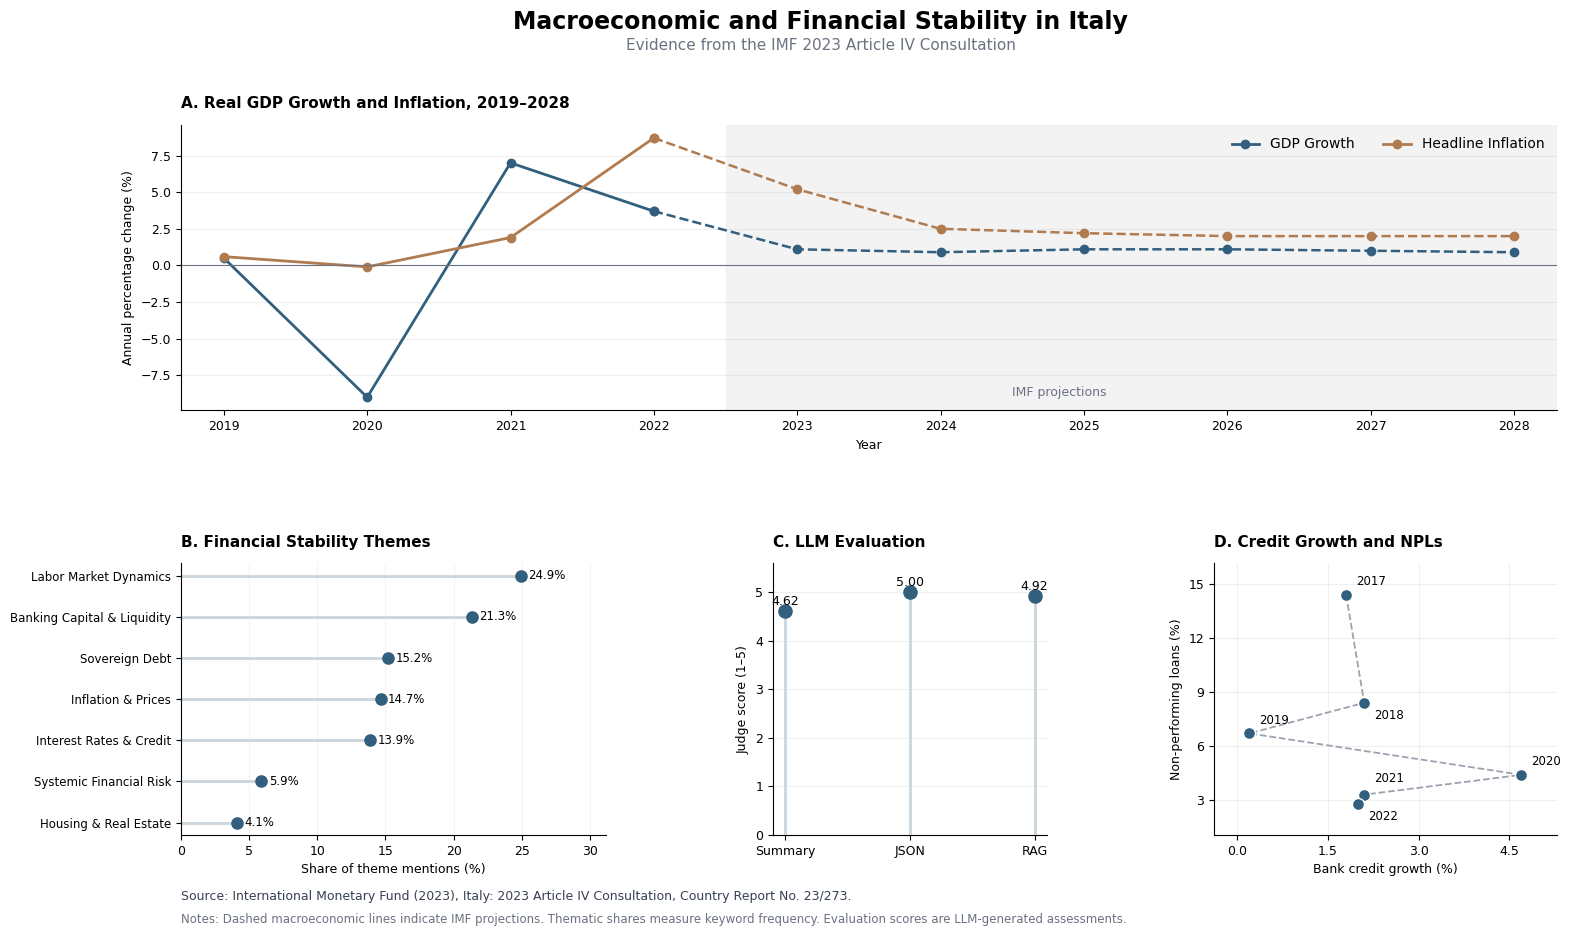

Academic dashboard created successfully.
Charts: 4
Resolution: 320 DPI
Saved: /content/italy_task1/dashboard/italy_research_dashboard.png


In [32]:
# TASK 4 — CELL 2: RESEARCH-PAPER STYLE DASHBOARD

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Academic colour scheme
BLUE = "#315F7D"
BROWN = "#B17B50"
GREY = "#6B7280"

fig = plt.figure(figsize=(16, 10), facecolor="white")

grid = fig.add_gridspec(
    2, 3,
    height_ratios=[1.05, 1],
    width_ratios=[1.55, 1, 1.25],
    left=0.10,
    right=0.96,
    top=0.85,
    bottom=0.14,
    hspace=0.55,
    wspace=0.48
)

fig.suptitle(
    "Macroeconomic and Financial Stability in Italy",
    fontsize=17,
    fontweight="bold",
    y=0.965
)

fig.text(
    0.5, 0.925,
    "Evidence from the IMF 2023 Article IV Consultation",
    ha="center",
    fontsize=11,
    color=GREY
)

# A. MACROECONOMIC PERFORMANCE — FULL WIDTH
ax1 = fig.add_subplot(grid[0, :])

historical = macro[macro["Year"] <= 2022]
forecast = macro[macro["Year"] >= 2022]

for indicator, colour in [
    ("GDP Growth", BLUE),
    ("Headline Inflation", BROWN)
]:
    ax1.plot(
        historical["Year"],
        historical[indicator],
        marker="o",
        linewidth=2,
        color=colour,
        label=indicator
    )

    ax1.plot(
        forecast["Year"],
        forecast[indicator],
        marker="o",
        linestyle="--",
        linewidth=1.8,
        color=colour
    )

ax1.axvspan(
    2022.5, 2028.3,
    color="#F0F1F2",
    alpha=0.8
)

ax1.axhline(0, color=GREY, linewidth=0.8)

ax1.set_title(
    "A. Real GDP Growth and Inflation, 2019–2028",
    loc="left",
    fontweight="bold",
    pad=12
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Annual percentage change (%)")
ax1.set_xticks(macro["Year"])
ax1.set_xlim(2018.7, 2028.3)
ax1.grid(axis="y", alpha=0.2)
ax1.legend(loc="upper right", frameon=False, ncol=2)

ax1.text(
    2024.5, ax1.get_ylim()[0] + 1,
    "IMF projections",
    fontsize=9,
    color=GREY
)


# B. FINANCIAL STABILITY THEMES — DOT PLOT
ax2 = fig.add_subplot(grid[1, 0])

theme_plot = themes.sort_values("Share")
ypos = range(len(theme_plot))

ax2.hlines(
    y=ypos,
    xmin=0,
    xmax=theme_plot["Share"],
    color="#CBD5DC",
    linewidth=2
)

ax2.scatter(
    theme_plot["Share"],
    list(ypos),
    color=BLUE,
    s=65,
    zorder=3
)

ax2.set_yticks(list(ypos))
ax2.set_yticklabels(theme_plot["Theme"], fontsize=8.5)

for i, value in enumerate(theme_plot["Share"]):
    ax2.text(
        value + 0.55,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=8.5
    )

ax2.set_xlim(0, theme_plot["Share"].max() * 1.25)
ax2.set_xlabel("Share of theme mentions (%)")
ax2.set_title(
    "B. Financial Stability Themes",
    loc="left",
    fontweight="bold",
    pad=12
)

ax2.grid(axis="x", alpha=0.15)
ax2.set_axisbelow(True)


# C. MODEL EVALUATION — POINT SCORES
ax3 = fig.add_subplot(grid[1, 1])

stage_names = {
    "Summarisation": "Summary",
    "JSON Extraction": "JSON",
    "RAG Evaluation": "RAG"
}

eval_plot = evaluation.copy()
eval_plot["Label"] = eval_plot["Stage"].map(stage_names)

for i, row in eval_plot.reset_index(drop=True).iterrows():
    ax3.vlines(
        i, 0, row["Judge Score"],
        color="#CBD5DC",
        linewidth=2
    )

    ax3.scatter(
        i,
        row["Judge Score"],
        color=BLUE,
        s=90,
        zorder=3
    )

    ax3.text(
        i,
        row["Judge Score"] + 0.13,
        f"{row['Judge Score']:.2f}",
        ha="center",
        fontsize=9
    )

ax3.set_xticks(range(len(eval_plot)))
ax3.set_xticklabels(eval_plot["Label"])

ax3.set_ylim(0, 5.6)
ax3.set_ylabel("Judge score (1–5)")

ax3.set_title(
    "C. LLM Evaluation",
    loc="left",
    fontweight="bold",
    pad=12
)

ax3.grid(axis="y", alpha=0.2)
ax3.set_axisbelow(True)


# D. BANKING RISK — HISTORICAL TRAJECTORY
ax4 = fig.add_subplot(grid[1, 2])

bank_plot = banking.sort_values("Year")

ax4.plot(
    bank_plot["Credit Growth"],
    bank_plot["NPL Ratio"],
    linestyle="--",
    color="#9CA3AF",
    linewidth=1.3,
    zorder=1
)

ax4.scatter(
    bank_plot["Credit Growth"],
    bank_plot["NPL Ratio"],
    color=BLUE,
    s=75,
    edgecolor="white",
    linewidth=1,
    zorder=3
)

offsets = {
    2017: (7, 7),
    2018: (7, -12),
    2019: (7, 7),
    2020: (7, 7),
    2021: (7, 9),
    2022: (7, -12)
}

for _, row in bank_plot.iterrows():
    year = int(row["Year"])

    ax4.annotate(
        str(year),
        (row["Credit Growth"], row["NPL Ratio"]),
        xytext=offsets.get(year, (6, 6)),
        textcoords="offset points",
        fontsize=8.5
    )

ax4.set_title(
    "D. Credit Growth and NPLs",
    loc="left",
    fontweight="bold",
    pad=12
)

ax4.set_xlabel("Bank credit growth (%)")
ax4.set_ylabel("Non-performing loans (%)")
ax4.grid(alpha=0.18)
ax4.xaxis.set_major_locator(MaxNLocator(5))
ax4.yaxis.set_major_locator(MaxNLocator(6))

ax4.margins(x=0.13, y=0.15)


# ACADEMIC SOURCE AND NOTES
fig.text(
    0.10, 0.075,
    "Source: International Monetary Fund (2023), "
    "Italy: 2023 Article IV Consultation, Country Report No. 23/273.",
    fontsize=9,
    color="#374151"
)

fig.text(
    0.10, 0.052,
    "Notes: Dashed macroeconomic lines indicate IMF projections. "
    "Thematic shares measure keyword frequency. "
    "Evaluation scores are LLM-generated assessments.",
    fontsize=8.5,
    color=GREY
)

# SAVE HIGH-RESOLUTION FIGURE
dashboard_path = DASH / "italy_research_dashboard.png"

fig.savefig(
    dashboard_path,
    dpi=320,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.25
)

plt.show()
plt.close(fig)

print("Academic dashboard created successfully.")
print("Charts: 4")
print("Resolution: 320 DPI")
print("Saved:", dashboard_path)

In [33]:
# EXTRA CREDIT — MULTI-QUERY RAG BENCHMARKING

import json
import re
import hashlib
import time
import numpy as np
from collections import defaultdict

EXTRA = OUT / "extra_credit"
EXTRA.mkdir(parents=True, exist_ok=True)
RESULT_FILE = EXTRA / "multi_query_evaluation.json"

# Generate three query variations using domain-specific terminology.
def query_variations(question):
    replacements = {
        "public debt": "sovereign debt and fiscal sustainability",
        "banking capital": "bank capital adequacy",
        "liquidity": "funding resilience",
        "credit risks": "loan quality and NPL risks",
        "GDP growth": "real economic growth",
        "inflation": "consumer price inflation",
        "forecasts": "economic projections"
    }

    alternative = question

    for old, new in replacements.items():
        alternative = re.sub(
            re.escape(old), new, alternative, flags=re.I
        )

    return list(dict.fromkeys([
        question,
        alternative if alternative != question
        else f"IMF staff assessment of {question}",
        f"Italy 2023 Article IV evidence: {question}"
    ]))


# Multi-query retrieval with Reciprocal Rank Fusion.
def multi_retrieve(question, k=4):
    vectors = embedder.encode(
        query_variations(question),
        normalize_embeddings=True
    ).astype(np.float32)

    distances, indices = index.search(
        vectors, min(12, index.ntotal)
    )

    scores = defaultdict(float)
    passages = {}

    for distance_row, index_row in zip(distances, indices):
        seen = set()

        for rank, (distance, idx) in enumerate(
            zip(distance_row, index_row), 1
        ):
            if idx < 0:
                continue

            chunk = rag_chunks[int(idx)]
            page = chunk["page"]

            if page in seen:
                continue

            seen.add(page)
            scores[page] += 1 / (60 + rank)

            if (page not in passages or
                    distance < passages[page]["distance"]):
                passages[page] = {
                    "pdf_page": page,
                    "chunk_id": chunk["id"],
                    "distance": float(distance),
                    "text": chunk["text"]
                }

    ranked = sorted(
        scores, key=scores.get, reverse=True
    )[:k]

    return [passages[p] for p in ranked]


JUDGE_SYSTEM = """
You are an independent IMF RAG evaluator.
Evaluate two answers against their respective retrieved evidence.
Assess faithfulness and completeness from 1 to 5.
Do not favour either retrieval method.
Penalise unsupported claims and missing information.
Return strictly valid JSON.
"""

# Resume completed evaluations when the inputs have not changed.
previous = json.loads(RESULT_FILE.read_text()) if RESULT_FILE.exists() else []
saved = {r["question"]: r for r in previous}
results = []

for question in tqdm(queries, desc="Benchmarking RAG"):

    baseline = retrieve_context(question, top_k=4)
    enhanced = multi_retrieve(question, k=4)

    fingerprint = hashlib.sha256(
        json.dumps(
            [MODEL, question, baseline, enhanced],
            sort_keys=True
        ).encode()
    ).hexdigest()

    if (question in saved and
            saved[question].get("fingerprint") == fingerprint):
        results.append(saved[question])
        continue

    # Generate answers using the same LLM and grounding procedure.
    answer_a = grounded_answer(question, baseline)
    answer_b = grounded_answer(question, enhanced)

    prompt = f"""
QUESTION: {question}

ANSWER A: {answer_a['answer']}
EVIDENCE A:
{json.dumps(baseline, ensure_ascii=False)}

ANSWER B: {answer_b['answer']}
EVIDENCE B:
{json.dumps(enhanced, ensure_ascii=False)}

Evaluate each answer independently against its own evidence.

Return exactly:
{{
  "A": {{"faithfulness": 1, "completeness": 1}},
  "B": {{"faithfulness": 1, "completeness": 1}},
  "explanation": "Brief comparative assessment"
}}
"""

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=JUDGE_SYSTEM,
                    temperature=0,
                    max_output_tokens=450,
                    response_mime_type="application/json"
                )
            )

            evaluation = json.loads(response.text)

            assert all(
                type(evaluation[method][metric]) is int
                and 1 <= evaluation[method][metric] <= 5
                for method in ("A", "B")
                for metric in ("faithfulness", "completeness")
            )
            break

        except Exception:
            if attempt == 2:
                raise
            time.sleep(3 * (attempt + 1))

    results.append({
        "question": question,
        "fingerprint": fingerprint,
        "single_query": evaluation["A"],
        "multi_query": evaluation["B"],
        "baseline_pages": [p["pdf_page"] for p in baseline],
        "multi_query_pages": [p["pdf_page"] for p in enhanced],
        "explanation": evaluation.get("explanation", "")
    })

    # Preserve completed results after each question.
    RESULT_FILE.write_text(
        json.dumps(results, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

# Compare evaluation scores across all questions.
print("\n" + "=" * 58)
print("EXTRA CREDIT — MULTI-QUERY RAG EVALUATION")
print("=" * 58)

summary = {}

for metric in ("faithfulness", "completeness"):
    single = np.mean([
        r["single_query"][metric] for r in results
    ])
    multi = np.mean([
        r["multi_query"][metric] for r in results
    ])

    summary[metric] = {
        "single_query": round(float(single), 2),
        "multi_query": round(float(multi), 2),
        "difference": round(float(multi - single), 2)
    }

    print(f"\n{metric.title()}")
    print(f"Single-Query RAG : {single:.2f}/5")
    print(f"Multi-Query RAG  : {multi:.2f}/5")
    print(f"Difference       : {multi - single:+.2f}")

(EXTRA / "benchmark_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("\nQuestions evaluated:", len(results))
print("Retrieval budget: 4 passages per method")
print("Evaluation: Gemini LLM-as-a-Judge")
print("Results saved:", EXTRA)
print("=" * 58)

Benchmarking RAG:   0%|          | 0/3 [00:00<?, ?it/s]


EXTRA CREDIT — MULTI-QUERY RAG EVALUATION

Faithfulness
Single-Query RAG : 5.00/5
Multi-Query RAG  : 5.00/5
Difference       : +0.00

Completeness
Single-Query RAG : 4.67/5
Multi-Query RAG  : 4.67/5
Difference       : +0.00

Questions evaluated: 3
Retrieval budget: 4 passages per method
Evaluation: Gemini LLM-as-a-Judge
Results saved: /content/italy_task1/extra_credit
